# Model 2073 — Synthetic SVXY −1x

#### **MScFE 690 Capstone -Group 17843**

**Authors**: Edgar NAVA-edgar.nava@grovwm.com & Celestin NYANDWI-celestinnyandwi48@gmail.com

This notebook applies the selected Model 2073 to synthetic SVXY −1x and compares its results with buy and hold. The model uses VIX states to determine entries, additional purchases and exits.

## 1. Model settings

The input files, `SVXY_synth-ONEx.csv` and `VIX_data.csv`, must be in the same folder as this notebook. The data cutoff is September 16, 2026. The synthetic series does not represent the actual SVXY ETF over the whole history.

Each period starts with USD 100,000 in cash and no position. Commission is USD 0.005 per share per side, with 0.10% slippage per side. Fractional shares are allowed; there is no borrowing or interest on cash.

The signals and the trailing stop use the current Close, and trades are modeled at that same Close with the costs described above. This is an execution assumption that we discuss in the Capstone document. A stop exit uses the observed Close, even when it is below the stop threshold.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
from IPython.display import display, Markdown

%matplotlib inline

DATA_DIR = Path.cwd()
DATA_CUTOFF = pd.Timestamp("2026-09-16")
INITIAL_CASH = 100_000.0
COMMISSION_PER_SHARE = 0.005
SLIPPAGE_PCT = 0.001
SESSIONS_PER_YEAR = 252
ANNUAL_RISK_FREE_RATE = 0.0
STATE_THRESHOLDS = [17.5, 22.540001, 28.805999000000003, 37.810001]

RULES = {
    "C2": {"vix_min": 23.0, "cash_fraction": 0.15,
           "target_nav": 0.70, "trailing_stop_pct": 0.20},
    "C3": {"vix_max": 28.0, "cash_fraction": 0.10,
           "invested_cash_fraction": 0.50, "trailing_stop_pct": 0.40},
    "V2": {"vix_min": 19.0},
    "V3": {"vix_max": 15.0},
}

PERIODS = {
    "Development": ("2011-10-04", "2020-12-31"),
    "Validation": ("2021-01-04", "2023-12-29"),
    "Test": ("2024-01-02", "2026-09-16"),
    "Full history": ("2011-10-04", "2026-09-16"),
}

MODEL_COLOR, BH_COLOR = "#226a95", "#ce7b29"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 120,
})

def blue_table(frame, caption, formatter=None):
    return (frame.style.format(formatter, na_rep="N/A")
        .set_caption(caption)
        .set_table_styles([
            {"selector": "caption", "props": [("text-align", "left"),
                ("color", "#255c80"), ("font-size", "16px"), ("padding", "8px 0")]},
            {"selector": "th", "props": [("background-color", "#255c80"),
                ("color", "white"), ("text-align", "left"), ("padding", "9px 12px")]},
            {"selector": "td", "props": [("padding", "9px 12px"), ("text-align", "right")]},
            {"selector": "tbody tr:nth-child(even)",
             "props": [("background-color", "#edf3f7")]},
            {"selector": "table", "props": [("border-collapse", "collapse")]},
        ]))

## 2. VIX states and trading rules

The five states use fixed VIX thresholds from the 55th, 76th, 90th and 96th percentiles of March 26, 2004–December 29, 2023. The limits are 17.5, 22.540001, 28.805999 and 37.810001. S1 is the lowest VIX range and S5 the highest. Equality belongs to the lower state. The previous state is calculated before splitting the periods.

| Rule | Condition and action |
|:---|:---|
| C2 | Exact S2 → S3 transition and VIX > 23. From cash: invest 15% of cash, including costs. With a position: buy to reach 70% of net asset value (NAV) after costs. If already at or above this level, do nothing. Trailing stop: 20%. |
| C3 | Exact S4 → S3 transition and VIX < 28. From cash: invest 10% of cash. With a position: invest 50% of remaining cash. Both include costs. Trailing stop: 40%. |
| V1 | Sell the whole position when Close ≤ the highest Close since the last purchase × (1 − trailing stop). |
| Exit flag | While invested, a transition from any higher state to S1 activates the exit flag. |
| V2 | With the flag active, an exact S1 → higher-state transition and VIX > 19 sells the whole position. |
| V3 | With the flag active, S1 and VIX < 15 sells the whole position, whether profitable or not. |

Each actual purchase resets the highest Close and applies its stop to the whole position; a signal without a purchase does not reset it. Purchases do not clear the exit flag. The C2 target is not a global exposure limit: C3 purchases and price appreciation can take exposure above 70%.

In [2]:
def read_close(filename):
    frame = (pd.read_csv(DATA_DIR / filename, parse_dates=["Date"])
             .set_index("Date").sort_index().loc[:DATA_CUTOFF, ["Close"]])
    if (not frame.index.is_unique or frame.empty
            or not np.isfinite(frame.Close).all() or not frame.Close.gt(0).all()):
        raise ValueError(f"Check dates and closing prices in {filename}.")
    return frame

vix = read_close("VIX_data.csv")
svxy = read_close("SVXY_synth-ONEx.csv")
vix["State"] = np.searchsorted(STATE_THRESHOLDS, vix.Close.to_numpy(), side="left") + 1
vix["Previous_state"] = vix.State.shift(1)
prices = svxy.join(vix.rename(columns={"Close": "VIX_Close"}), how="left")
if prices.isna().any().any():
    raise ValueError("Missing aligned data or preceding VIX state.")

period_rows = []
for label, (start, end) in PERIODS.items():
    data = prices.loc[start:end]
    if data.empty or data.index[0] != pd.Timestamp(start) or data.index[-1] != pd.Timestamp(end):
        raise ValueError(f"Incomplete dates for {label}.")
    period_rows.append({"Period": label, "Start": start, "End": end, "Sessions": len(data)})
display(blue_table(pd.DataFrame(period_rows).set_index("Period"), "Evaluation periods"))

,Start,End,Sessions
Period,,,
Development,2011-10-04,2020-12-31,2327
Validation,2021-01-04,2023-12-29,753
Test,2024-01-02,2026-09-16,679
Full history,2011-10-04,2026-09-16,3759


## 3. Portfolio accounting and performance measures

Equity is cash plus the position valued at Close. Buy and hold invests all initial cash at the first Close, with the same costs. Open positions are valued at the final Close without a forced sale.

CAGR uses calendar days / 365.25. Sharpe uses daily net returns, sample standard deviation, 252 sessions per year and a zero risk-free rate. Drawdown includes the initial capital in the running peak. Calmar is CAGR divided by the absolute maximum drawdown over the same period; undefined values are shown as N/A.

In [3]:
def finish_account(account):
    account = account.copy()
    account["Position_value"] = account.Units * account.Close
    account["Equity"] = account.Cash + account.Position_value
    account["Daily_return"] = account.Equity.pct_change(fill_method=None)
    account.loc[account.index[0], "Daily_return"] = account.Equity.iloc[0] / INITIAL_CASH - 1
    account["Drawdown"] = account.Equity / account.Equity.cummax().clip(lower=INITIAL_CASH) - 1
    account["Exposure"] = account.Position_value / account.Equity
    return account


def run_buy_and_hold(data):
    account = data[["Close"]].copy()
    first_close = float(account.Close.iloc[0])
    execution_price = first_close * (1 + SLIPPAGE_PCT)
    units = INITIAL_CASH / (execution_price + COMMISSION_PER_SHARE)
    account["Cash"], account["Units"] = 0.0, units
    account["Commission"], account["Slippage_cost"] = 0.0, 0.0
    account.loc[account.index[0], "Commission"] = units * COMMISSION_PER_SHARE
    account.loc[account.index[0], "Slippage_cost"] = units * first_close * SLIPPAGE_PCT
    return finish_account(account)


def performance(account):
    final = float(account.Equity.iloc[-1])
    years = (account.index[-1] - account.index[0]).days / 365.25
    cagr = (final / INITIAL_CASH) ** (1 / years) - 1
    max_drawdown = float(account.Drawdown.min())
    daily_rf = (1 + ANNUAL_RISK_FREE_RATE) ** (1 / SESSIONS_PER_YEAR) - 1
    excess = account.Daily_return - daily_rf
    volatility = float(excess.std(ddof=1))
    return pd.Series({
        "Initial equity ($)": INITIAL_CASH,
        "Final equity ($)": final,
        "Total profit ($)": final - INITIAL_CASH,
        "Total return": final / INITIAL_CASH - 1,
        "Annualized return (CAGR)": cagr,
        "Sharpe ratio": np.sqrt(SESSIONS_PER_YEAR) * excess.mean() / volatility
            if volatility > 0 else np.nan,
        "Calmar ratio": cagr / abs(max_drawdown)
            if np.isfinite(cagr) and max_drawdown < 0 else np.nan,
        "Drawdown at final date": float(account.Drawdown.iloc[-1]),
        "Maximum drawdown": max_drawdown,
    })

## 4. Trading engine

Daily priority is V1, then the exit flag and V2/V3, then purchases. A sale ends trading for that day and clears the position, flag and stop. Each run starts from cash; earlier VIX observations provide only the previous-state context. Daily accounts and trade records remain available in `results`.

In [4]:
def run_model(data):
    cash, units, flag = INITIAL_CASH, 0.0, 0
    peak_close = active_stop_pct = np.nan
    records, orders = [], []
    cash_tolerance = max(1.0, INITIAL_CASH) * 1e-12

    for date, row in data.iterrows():
        price, vix_close = float(row.Close), float(row.VIX_Close)
        state, previous = int(row.State), int(row.Previous_state)
        equity_before = cash + units * price
        side, rule_id = None, ""
        target, execution_price = np.nan, np.nan
        commission, slippage_cost = 0.0, 0.0

        # Existing stops take priority over all other signals.
        if units > 0:
            peak_close = max(peak_close, price)
            if price <= peak_close * (1 - active_stop_pct):
                side, rule_id = "SELL", "V1"

        if side is None and units > 0:
            if state == 1 and previous in (2, 3, 4, 5):
                flag = 1
            if flag == 1:
                if previous == 1 and state > 1 and vix_close > RULES["V2"]["vix_min"]:
                    side, rule_id = "SELL", "V2"
                elif state == 1 and vix_close < RULES["V3"]["vix_max"]:
                    side, rule_id = "SELL", "V3"

        if side == "SELL":
            quantity = units
            execution_price = price * (1 - SLIPPAGE_PCT)
            commission = quantity * COMMISSION_PER_SHARE
            slippage_cost = quantity * price * SLIPPAGE_PCT
            cash += quantity * execution_price - commission
            units, flag = 0.0, 0
            peak_close = active_stop_pct = np.nan
        else:
            if previous == 2 and state == 3 and vix_close > RULES["C2"]["vix_min"]:
                rule_id = "C2"
                target = RULES[rule_id]["target_nav"] if units > 0 else RULES[rule_id]["cash_fraction"]
            elif previous == 4 and state == 3 and vix_close < RULES["C3"]["vix_max"]:
                rule_id = "C3"
                target = RULES[rule_id]["invested_cash_fraction"] if units > 0 else RULES[rule_id]["cash_fraction"]

            if np.isfinite(target):
                execution_price = price * (1 + SLIPPAGE_PCT)
                all_in_price = execution_price + COMMISSION_PER_SHARE
                if units == 0 or rule_id == "C3":
                    quantity = target * cash / all_in_price
                else:
                    # C2 targets position value / NAV after transaction costs.
                    gap = max(0.0, target * equity_before - units * price)
                    quantity = min(cash / all_in_price,
                        gap / (price + target * (price * SLIPPAGE_PCT + COMMISSION_PER_SHARE)))

                if quantity * all_in_price > cash_tolerance:
                    side = "BUY"
                    commission = quantity * COMMISSION_PER_SHARE
                    slippage_cost = quantity * price * SLIPPAGE_PCT
                    cash -= quantity * execution_price + commission
                    units += quantity
                    active_stop_pct = RULES[rule_id]["trailing_stop_pct"]
                    peak_close = price

        # Remove floating-point residue without allowing borrowing.
        if -cash_tolerance <= cash < 0:
            cash = 0.0
        if cash < 0 or units < 0:
            raise ArithmeticError(f"Negative cash or units at {date}.")
        if units == 0:
            flag = 0
        stop = peak_close * (1 - active_stop_pct) if units > 0 else np.nan

        if side is not None:
            orders.append({
                "Date": date, "Side": side, "Rule ID": rule_id,
                "Close": price, "Execution price": execution_price, "Units": quantity,
                "Commission ($)": commission, "Slippage ($)": slippage_cost,
                "Cash after": cash, "Units after": units,
            })
        records.append({
            "Date": date, "Close": price, "VIX_Close": vix_close,
            "State": state, "Previous_state": previous,
            "Cash": cash, "Units": units, "Commission": commission,
            "Slippage_cost": slippage_cost, "Peak_close": peak_close,
            "Stop_threshold": stop, "Trailing_stop_pct": active_stop_pct,
            "Flag": flag, "Action": side or "HOLD", "Rule ID": rule_id,
        })

    account = finish_account(pd.DataFrame(records).set_index("Date"))
    order_columns = ["Date", "Side", "Rule ID", "Close", "Execution price", "Units",
                     "Commission ($)", "Slippage ($)", "Cash after", "Units after"]
    return account, pd.DataFrame(orders, columns=order_columns)

In [5]:
def show_results(label):
    result = results[label]
    account, benchmark, orders = result["account"], result["benchmark"], result["orders"]
    metrics = result["metrics"]
    formatted = metrics.copy().astype(object)
    for metric in metrics.index:
        if "($)" in metric:
            formatter = lambda value: f"${value:,.2f}"
        elif metric in ("Sharpe ratio", "Calmar ratio"):
            formatter = lambda value: f"{value:.3f}"
        else:
            formatter = lambda value: f"{value:.2%}"
        formatted.loc[metric] = metrics.loc[metric].map(
            lambda value: formatter(value) if pd.notna(value) else "N/A")
    display(blue_table(formatted, f"{label} — performance after costs"))
    buys, sells = orders.Side.eq("BUY"), orders.Side.eq("SELL")
    display(Markdown(f"**Model trades:** {buys.sum()} purchases and {sells.sum()} sales, "
                     f"including {orders['Rule ID'].eq('V1').sum()} trailing-stop exits."))

    fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True,
                             gridspec_kw={"height_ratios": [2, 1, 1.15]}, layout="constrained")
    fig.suptitle(f"{label} — Model 2073 and buy and hold", fontsize=15, color="#255c80")
    for frame, name, color in [(account, "Model 2073", MODEL_COLOR),
                               (benchmark, "Buy and hold", BH_COLOR)]:
        axes[0].plot(frame.index, frame.Equity, label=name, color=color, linewidth=1.7)
        axes[1].plot(frame.index, frame.Drawdown, label=name, color=color, linewidth=1.25)
    axes[0].set_ylabel("Equity ($)")
    axes[0].yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))
    axes[0].legend(loc="upper left")
    axes[1].set_ylabel("Drawdown")
    axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
    axes[2].plot(account.index, account.VIX_Close, color="#657c8b", linewidth=1, label="VIX")
    for mask, marker, color, name in [(buys, "^", "#277c6b", "Model buy"),
                                     (sells, "v", "#ad4e45", "Model sell")]:
        dates = pd.DatetimeIndex(orders.loc[mask, "Date"])
        axes[2].scatter(dates, account.loc[dates, "VIX_Close"], marker=marker,
                        color=color, s=38, label=name, zorder=3)
    axes[2].set_ylabel("VIX Close")
    axes[2].set_xlabel("Date")
    axes[2].legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=3,
                   fontsize=9, frameon=False, borderaxespad=0)
    for ax in axes:
        ax.grid(alpha=0.18)
    plt.show()


results = {}
for label, (start, end) in PERIODS.items():
    data = prices.loc[start:end]
    account, orders = run_model(data)
    benchmark = run_buy_and_hold(data)
    results[label] = {
        "account": account, "benchmark": benchmark, "orders": orders,
        "metrics": pd.DataFrame({"Model 2073": performance(account),
                                  "Buy and hold": performance(benchmark)}),
    }

## 5. Development — Model 2073 versus buy and hold

,Model 2073,Buy and hold
Initial equity ($),"$100,000.00","$100,000.00"
Final equity ($),"$496,956.75","$710,137.84"
Total profit ($),"$396,956.75","$610,137.84"
Total return,396.96%,610.14%
Annualized return (CAGR),18.94%,23.63%
Sharpe ratio,0.912,0.673
Calmar ratio,0.831,0.269
Drawdown at final date,-3.32%,-74.01%
Maximum drawdown,-22.79%,-87.91%


**Model trades:** 32 purchases and 13 sales, including 2 trailing-stop exits.

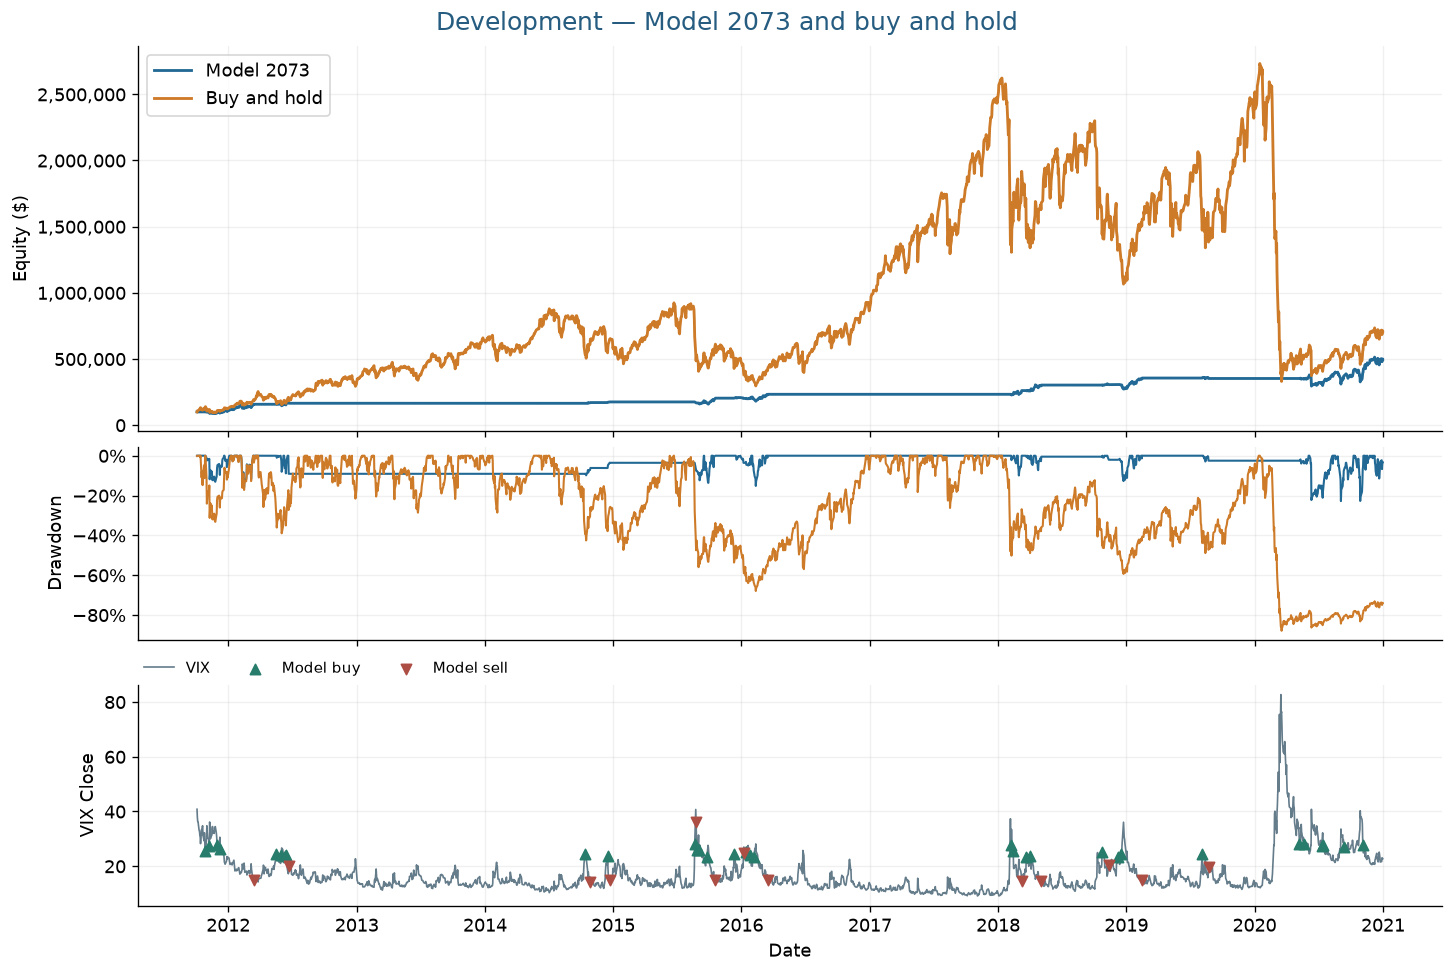

In [6]:
show_results("Development")

## 6. Validation — the same model versus buy and hold

The rules and costs are unchanged.

,Model 2073,Buy and hold
Initial equity ($),"$100,000.00","$100,000.00"
Final equity ($),"$228,423.69","$471,074.00"
Total profit ($),"$128,423.69","$371,074.00"
Total return,128.42%,371.07%
Annualized return (CAGR),31.92%,68.17%
Sharpe ratio,0.942,1.116
Calmar ratio,1.014,1.205
Drawdown at final date,0.00%,-0.21%
Maximum drawdown,-31.49%,-56.58%


**Model trades:** 19 purchases and 8 sales, including 5 trailing-stop exits.

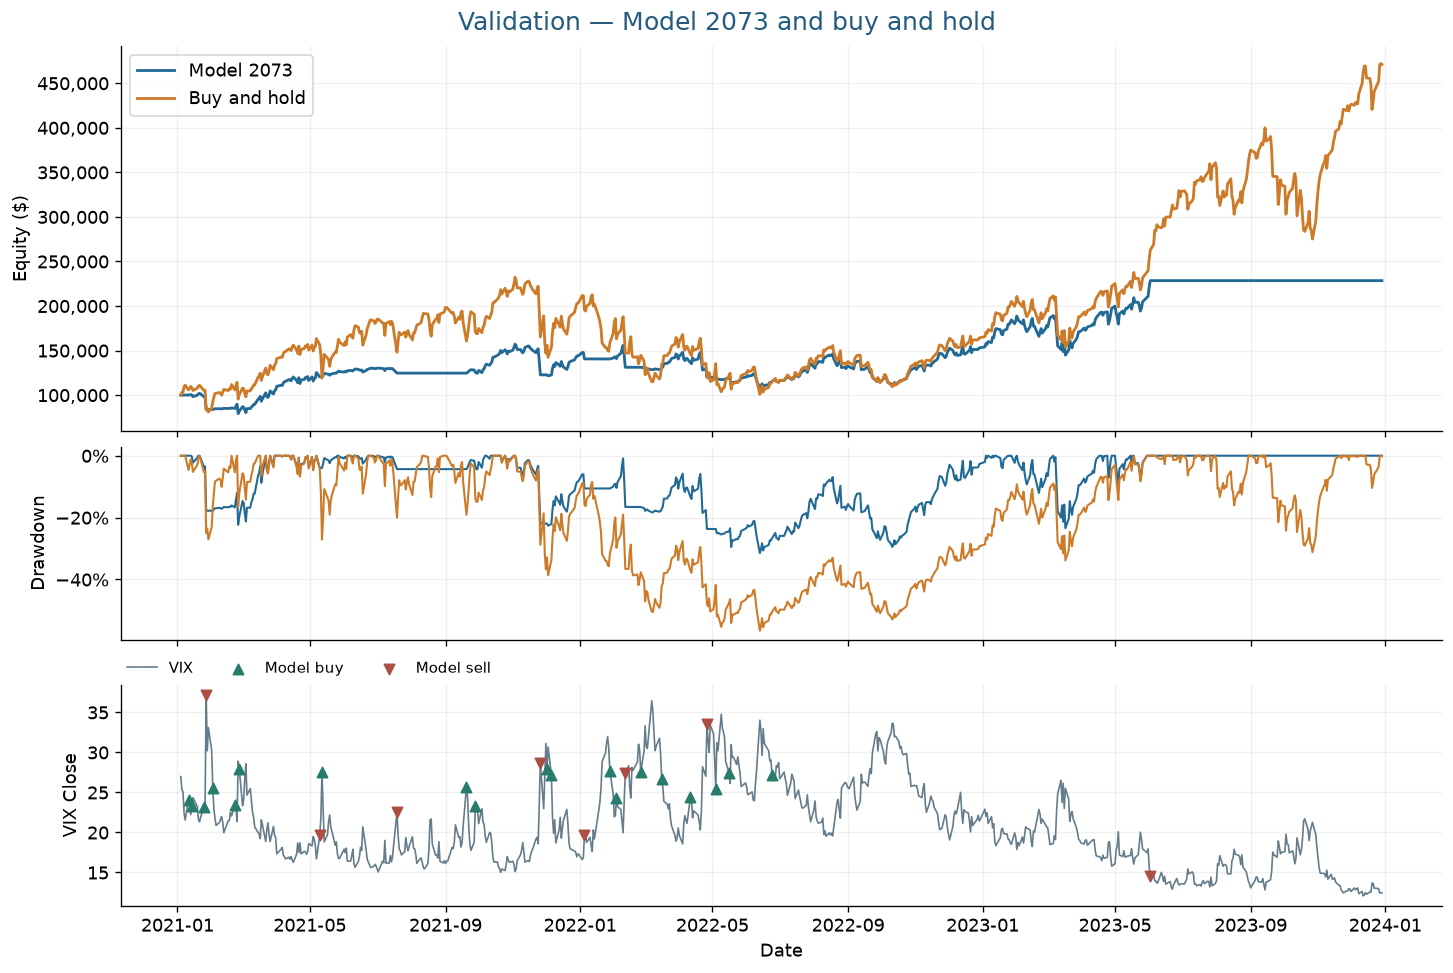

In [7]:
show_results("Validation")

## 7. Test — the same model versus buy and hold

The test period starts in January 2024 with fixed parameters.

,Model 2073,Buy and hold
Initial equity ($),"$100,000.00","$100,000.00"
Final equity ($),"$126,351.27","$96,815.83"
Total profit ($),"$26,351.27","$-3,184.17"
Total return,26.35%,-3.18%
Annualized return (CAGR),9.03%,-1.19%
Sharpe ratio,0.552,0.378
Calmar ratio,0.404,-0.015
Drawdown at final date,-7.08%,-34.89%
Maximum drawdown,-22.35%,-77.97%


**Model trades:** 9 purchases and 5 sales, including 2 trailing-stop exits.

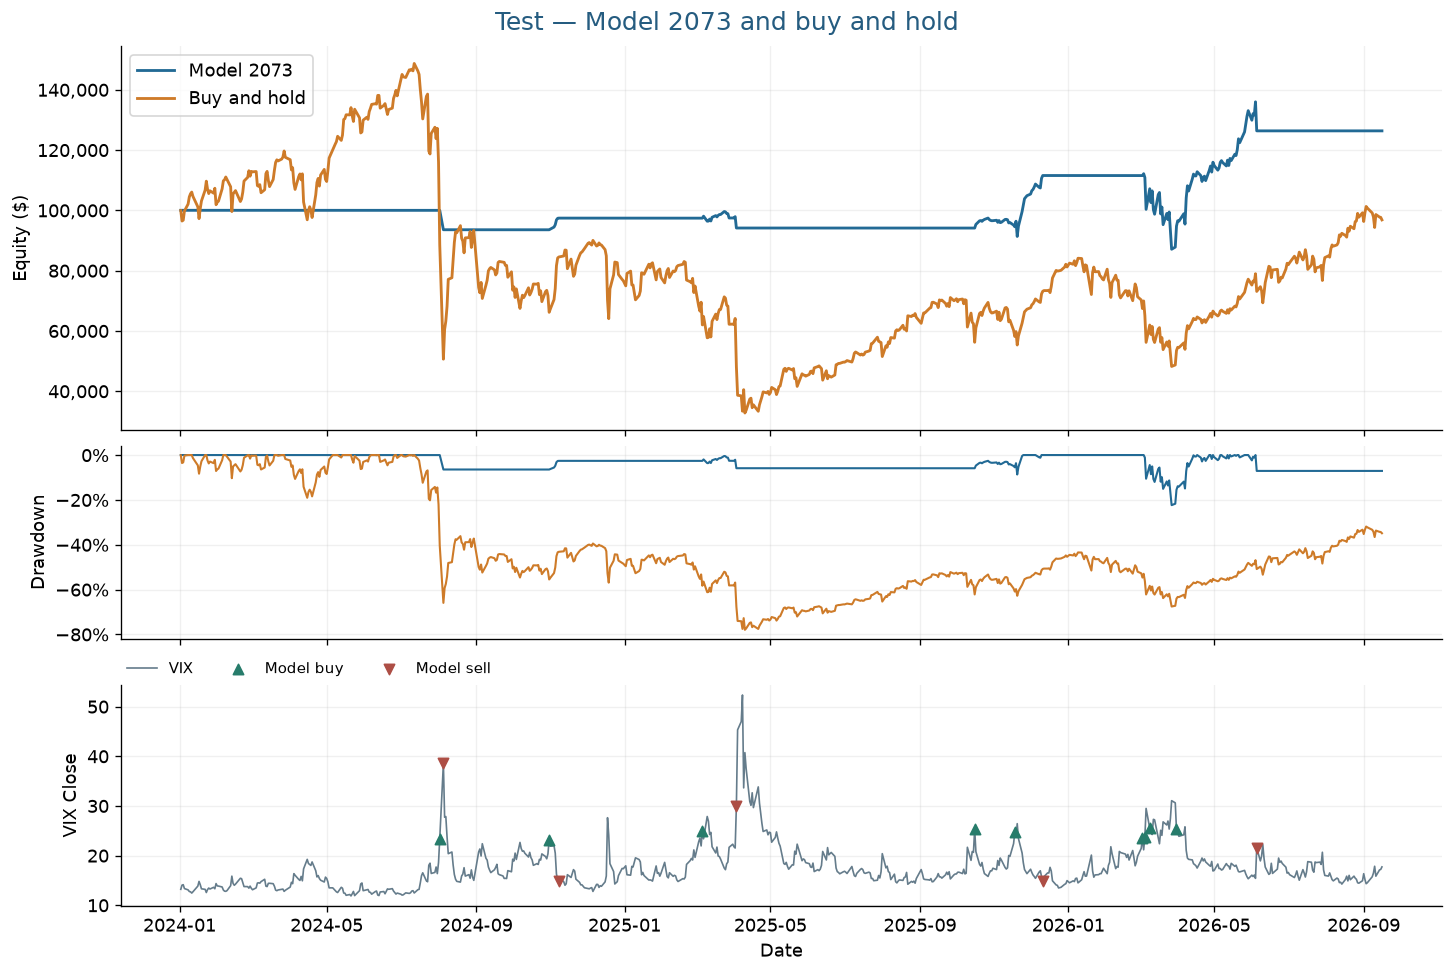

In [8]:
show_results("Test")

## 8. Full history — continuous simulation

This run starts once with USD 100,000 and continues through the full history. It does not concatenate or restart the three previous accounts and is not an independent test.

,Model 2073,Buy and hold
Initial equity ($),"$100,000.00","$100,000.00"
Final equity ($),"$1,703,780.60","$2,966,290.34"
Total profit ($),"$1,603,780.60","$2,866,290.34"
Total return,1603.78%,2866.29%
Annualized return (CAGR),20.88%,25.45%
Sharpe ratio,0.859,0.695
Calmar ratio,0.663,0.289
Drawdown at final date,-7.08%,-34.89%
Maximum drawdown,-31.49%,-87.91%


**Model trades:** 56 purchases and 25 sales, including 8 trailing-stop exits.

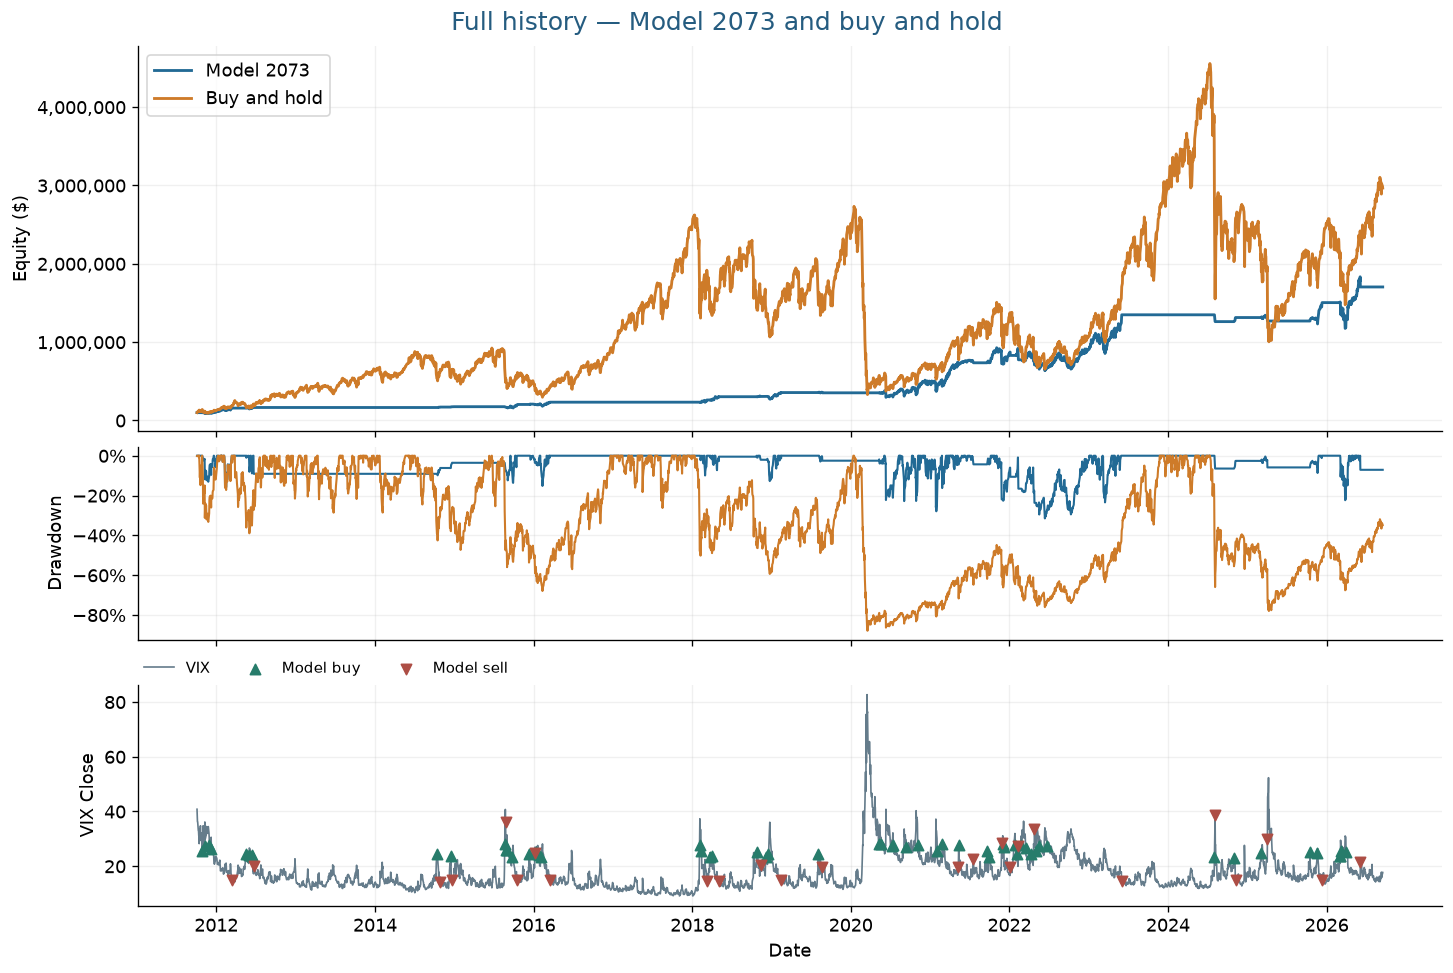

In [9]:
show_results("Full history")